In [1]:
%pip install pandas numpy scikit-learn gradio flask matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install gradio flask


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gradio as gr
from flask import Flask, request, render_template_string
from werkzeug.serving import make_server
import threading
import time

print("Libraries ready")


Libraries ready


In [4]:
auto_df = pd.read_csv("auto-mpg.csv")

auto_df.columns = (
    auto_df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)
print("Dataset shape:", auto_df.shape)
print("Columns:", auto_df.columns.tolist())
display(auto_df.head())

Dataset shape: (398, 9)
Columns: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [5]:
auto_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin"
]
auto_target = "mpg"

required = auto_features + [auto_target]
missing_columns = [c for c in required if c not in auto_df.columns]

if missing_columns:
    raise ValueError(
        f"Required columns not exist: {missing_columns}. "
        "Chk CSV file colmn."
    )

for col in required:
    auto_df[col] = pd.to_numeric(
        auto_df[col].replace("?", np.nan),
        errors="coerce"
    )
auto_df = auto_df.dropna(subset=[auto_target]).copy()

X_auto = auto_df[auto_features]
y_auto = auto_df[auto_target]

print("Missing values before imputation:")
print(X_auto.isnull().sum())
print("\nRows available:", len(auto_df))

Missing values before imputation:
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

Rows available: 398


In [6]:
X_auto_train, X_auto_test, y_auto_train, y_auto_test = train_test_split(X_auto, y_auto,test_size=0.20,random_state=42)
print("Training rows:", len(X_auto_train))
print("Testing rows:", len(X_auto_test))


Training rows: 318
Testing rows: 80


In [7]:
auto_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

auto_model.fit(X_auto_train, y_auto_train)
print("Auto MPG Linear Regression model trained successfully")

Auto MPG Linear Regression model trained successfully


In [8]:
y_auto_pred = auto_model.predict(X_auto_test)

auto_mae = mean_absolute_error(y_auto_test, y_auto_pred)
auto_mse = mean_squared_error(y_auto_test, y_auto_pred)
auto_rmse = np.sqrt(auto_mse)
auto_r2 = r2_score(y_auto_test, y_auto_pred)

print("AUTO MPG MODEL RESULTS")
print(f"MAE:  {auto_mae:.3f} MPG")
print(f"MSE:  {auto_mse:.3f}")
print(f"RMSE: {auto_rmse:.3f} MPG")
print(f"R²:   {auto_r2:.4f}")

auto_results = pd.DataFrame({
    "Actual MPG": y_auto_test.to_numpy(),
    "Predicted MPG": y_auto_pred.round(2)
})
display(auto_results.head(10))


AUTO MPG MODEL RESULTS
MAE:  2.256 MPG
MSE:  8.198
RMSE: 2.863 MPG
R²:   0.8475


,Actual MPG,Predicted MPG
0,33.0,32.88
1,28.0,29.55
2,19.0,21.37
3,13.0,16.80
4,14.0,12.50
5,27.0,27.20
6,24.0,27.90
7,13.0,9.77
8,17.0,16.88
9,21.0,22.05


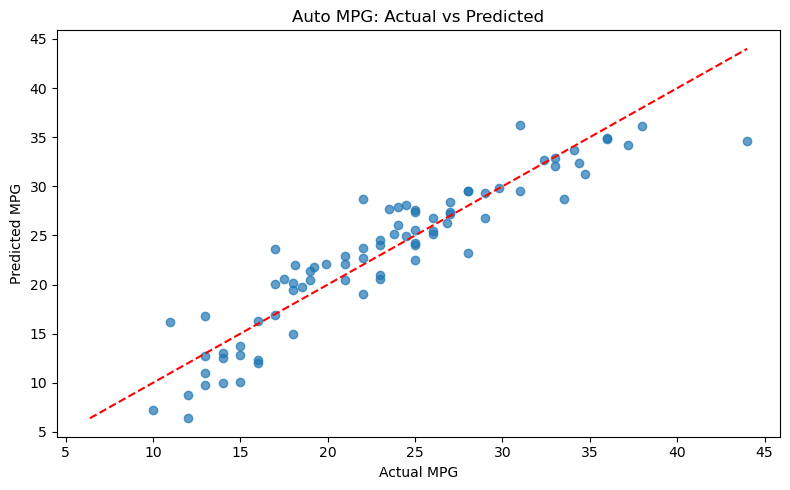

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(y_auto_test, y_auto_pred, alpha=0.7)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Auto MPG: Actual vs Predicted")

low = min(y_auto_test.min(), y_auto_pred.min())
high = max(y_auto_test.max(), y_auto_pred.max())
plt.plot([low, high], [low, high], "r--")

plt.tight_layout()
plt.show()

In [10]:
def predict_mpg(cylinders, displacement, horsepower,
                weight, acceleration, model_year, origin):
    values = [
        cylinders, displacement, horsepower, weight,
        acceleration, model_year, origin
    ]

    if any(v is None or not np.isfinite(v) for v in values):
       return "Please enter valid numeric values."
    if (
        cylinders <= 0 or displacement <= 0 or horsepower <= 0
        or weight <= 0 or acceleration <= 0
        or not 70 <= model_year <= 99
        or not 1 <= origin <= 3
    ):
        return "Please enter valid car details. Model year: 70-99, origin: 1-3."

    car = pd.DataFrame([{
        "cylinders": cylinders,
        "displacement": displacement,
        "horsepower": horsepower,
        "weight": weight,
        "acceleration": acceleration,
        "model_year": model_year,
        "origin": origin
    }])

    prediction = auto_model.predict(car)[0]

    return (
        f"Predicted Fuel Efficiency: {prediction:.2f} MPG\n"
        f"Model MAE: {auto_mae:.2f} MPG\n"
        f"Model RMSE: {auto_rmse:.2f} MPG\n"
        f"Model R²: {auto_r2:.4f}"
    )
auto_demo = gr.Interface(
    fn=predict_mpg,
    inputs=[
        gr.Number(label="Cylinders", value=4),
        gr.Number(label="Displacement", value=140),
        gr.Number(label="Horsepower", value=90),
        gr.Number(label="Weight (lbs)", value=2500),
        gr.Number(label="Acceleration", value=15),
        gr.Number(label="Model Year (70-99)", value=82),
        gr.Number(label="Origin (1=USA, 2=Europe, 3=Japan)", value=1)
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Car Fuel Efficiency Prediction",
    description="Predict car fuel efficiency using Linear Regression."
)
auto_demo.launch()


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [11]:
auto_flask_app = Flask("auto_mpg_app")
auto_html = """
<!DOCTYPE html>
<html>
<head>
    <title>Auto MPG Prediction</title>
</head>
<body style="font-family:Arial; max-width:650px; margin:40px auto;">
    <h1>Car Fuel Efficiency Prediction</h1>

    <form method="POST">
        <label>Cylinders:</label><br>
        <input type="number" name="cylinders" value="4" min="1" required><br><br>

        <label>Displacement:</label><br>
        <input type="number" name="displacement" value="140" min="1" step="any" required><br><br>

        <label>Horsepower:</label><br>
        <input type="number" name="horsepower" value="90" min="1" step="any" required><br><br>

        <label>Weight (lbs):</label><br>
        <input type="number" name="weight" value="2500" min="1" step="any" required><br><br>

        <label>Acceleration:</label><br>
        <input type="number" name="acceleration" value="15" min="1" step="any" required><br><br>

        <label>Model Year (70-99):</label><br>
        <input type="number" name="model_year" value="82" min="70" max="99" required><br><br>

        <label>Origin (1=USA, 2=Europe, 3=Japan):</label><br>
        <input type="number" name="origin" value="1" min="1" max="3" required><br><br>

        <button type="submit">Predict MPG</button>
    </form>
    {% if result %}
        <h2>Prediction Result</h2>
        <pre>{{ result }}</pre>
    {% endif %}
</body>
</html>
"""
@auto_flask_app.route("/", methods=["GET", "POST"])
def auto_home():
    result = ""
    if request.method == "POST":
        try:
            result = predict_mpg(
                float(request.form["cylinders"]),
                float(request.form["displacement"]),
                float(request.form["horsepower"]),
                float(request.form["weight"]),
                float(request.form["acceleration"]),
                float(request.form["model_year"]),
                float(request.form["origin"])
            )
        except (ValueError, TypeError):
            result = "Please enter valid numeric values."

    return render_template_string(auto_html, result=result)

print("Auto MPG Flask app created")

Auto MPG Flask app created


In [12]:
auto_flask_server = make_server("127.0.0.1", 5001, auto_flask_app)

auto_flask_thread = threading.Thread(
    target=auto_flask_server.serve_forever,
    daemon=True
)
auto_flask_thread.start()
time.sleep(1)

print("Auto MPG Flask server running:", auto_flask_thread.is_alive())
print("Open: http://127.0.0.1:5001")

Auto MPG Flask server running: True
Open: http://127.0.0.1:5001


In [13]:
auto_flask_server.shutdown()
print("Auto MPG Flask server stopped.")


Auto MPG Flask server stopped.
